In [1]:
from pathlib import Path
import json
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from sklearn.linear_model import Ridge
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import Pipeline
    from sklearn.metrics import mean_absolute_error, mean_squared_error
except ImportError as e:
    raise ImportError(
        "Este notebook requer scikit-learn. Instale com: pip install scikit-learn"
    ) from e

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

ROOT = Path.cwd()
OUT1 = ROOT / "outputs_fame_gpu"
OUT2 = ROOT / "outputs_fame_gpu_02"
OUT2.mkdir(exist_ok=True)

PRIMARY_GPU = "A100-SXM4-80GB"
HORIZON = 4
DEV_VALIDATION_DAYS = 7
MIN_TRAIN_DAYS = 28

RIDGE_ALPHAS = [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]

print("PRIMARY_GPU:", PRIMARY_GPU)
print("HORIZON:", HORIZON)
print("OUT2:", OUT2.resolve())

PRIMARY_GPU: A100-SXM4-80GB
HORIZON: 4
OUT2: C:\Users\tiago\Dropbox\Artigos\FAME\FAME\Artigo 2 - AOR\FAME_GPU\outputs_fame_gpu_02


In [2]:
def locate_outputs():
    candidates = [
        ROOT / "outputs_fame_gpu",
        ROOT / "outputs_fame_gpu_extracted" / "outputs_fame_gpu",
        Path("/mnt/data/outputs_fame_gpu"),
    ]
    for p in candidates:
        if (p / "fame_windows_7d.csv").exists():
            return p
    raise FileNotFoundError(
        "Não encontrei outputs_fame_gpu. Coloque a pasta gerada pelo Notebook 01 "
        "no mesmo diretório deste notebook."
    )

OUT1 = locate_outputs()
print("Usando:", OUT1.resolve())

windows = pd.read_csv(
    OUT1 / "fame_windows_7d.csv",
    parse_dates=[
        "D_start", "D_end_exclusive",
        "C_start", "C_end_exclusive",
        "E_start", "E_end_exclusive"
    ]
)

panel_file_parquet = OUT1 / "panel_hourly_gpu_priority.parquet"
panel_file_csv = OUT1 / "panel_hourly_gpu_priority.csv.gz"

if panel_file_parquet.exists():
    panel = pd.read_parquet(panel_file_parquet)
elif panel_file_csv.exists():
    panel = pd.read_csv(panel_file_csv, compression="gzip")
else:
    raise FileNotFoundError("Painel horário do Notebook 01 não encontrado.")

panel["hour_gfs"] = pd.to_datetime(panel["hour_gfs"])

inventory = pd.read_csv(OUT1 / "gpu_inventory.csv")
support = pd.read_csv(OUT1 / "gpu_window_support.csv")

display(windows)
display(
    support[support["gpu_model"] == PRIMARY_GPU]
)

Usando: C:\Users\tiago\Dropbox\Artigos\FAME\FAME\Artigo 2 - AOR\FAME_GPU\outputs_fame_gpu


,replication,D_start,D_end_exclusive,C_start,C_end_exclusive,E_start,E_end_exclusive
0,R01,2024-03-01,2024-04-26,2024-04-26,2024-05-03,2024-05-03,2024-05-10
1,R02,2024-03-01,2024-05-10,2024-05-10,2024-05-17,2024-05-17,2024-05-24
2,R03,2024-03-01,2024-05-24,2024-05-24,2024-05-31,2024-05-31,2024-06-07
3,R04,2024-03-01,2024-06-07,2024-06-07,2024-06-14,2024-06-14,2024-06-21
4,R05,2024-03-01,2024-06-21,2024-06-21,2024-06-28,2024-06-28,2024-07-05
5,R06,2024-03-01,2024-07-05,2024-07-05,2024-07-12,2024-07-12,2024-07-19
6,R07,2024-03-01,2024-07-19,2024-07-19,2024-07-26,2024-07-26,2024-08-02
7,R08,2024-03-01,2024-08-02,2024-08-02,2024-08-09,2024-08-09,2024-08-16
8,R09,2024-03-01,2024-08-16,2024-08-16,2024-08-23,2024-08-23,2024-08-30


,gpu_model,min_C_hp,min_E_hp,min_C_spot,min_E_spot,median_jobs,median_orgs
1,A100-SXM4-80GB,3724,4492,588,726,6372.5,18.0


In [3]:
hp = panel[
    (panel["gpu_model"] == PRIMARY_GPU) &
    (panel["job_type"] == "HP")
].copy()

series = (
    hp.groupby("hour_gfs")["requested_gpus"]
    .sum()
    .sort_index()
)

full_index = pd.date_range(
    panel["hour_gfs"].min().floor("h"),
    panel["hour_gfs"].max().ceil("h"),
    freq="h"
)

y = series.reindex(full_index, fill_value=0.0)
y.name = "hp_submitted_gpus"

print(y.describe())

count    4418.000000
mean      155.798778
std       179.394512
min         2.000000
25%        42.000000
50%        93.000000
75%       207.000000
max      2252.000000
Name: hp_submitted_gpus, dtype: float64


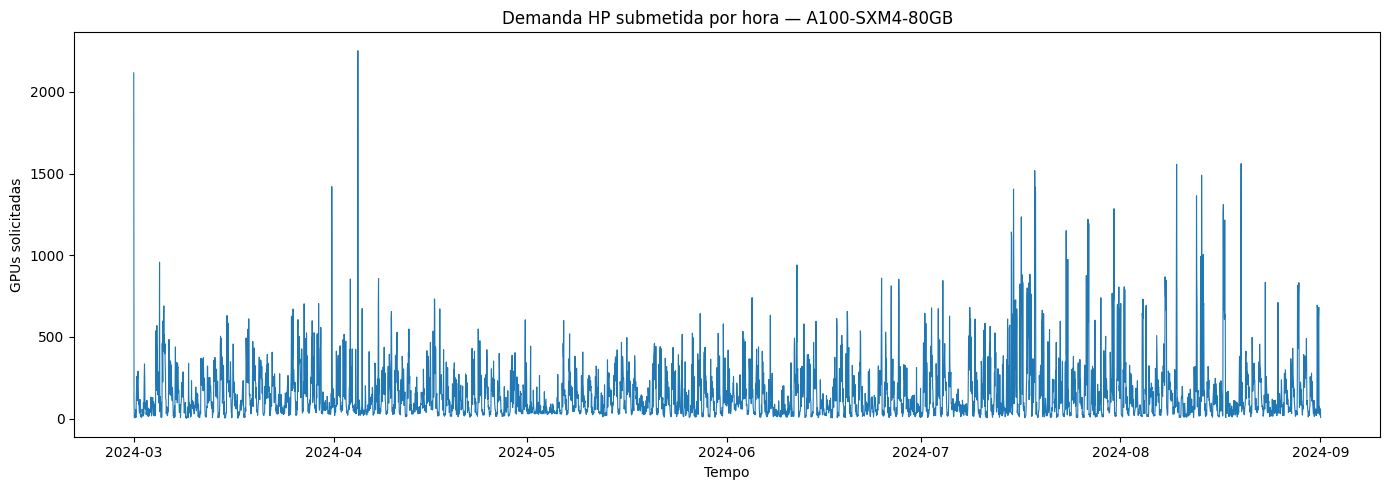

In [4]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y.index, y.values, linewidth=0.8)
ax.set_title(f"Demanda HP submetida por hora — {PRIMARY_GPU}")
ax.set_xlabel("Tempo")
ax.set_ylabel("GPUs solicitadas")
plt.tight_layout()
plt.show()

In [5]:
LAGS = [1, 2, 3, 4, 6, 12, 24, 48, 72, 168]
ROLL_WINDOWS = [6, 24, 168]

def build_features(y: pd.Series) -> pd.DataFrame:
    df = pd.DataFrame(index=y.index)
    df["y_now"] = y

    for lag in LAGS:
        df[f"lag_{lag}"] = y.shift(lag)

    
    past = y.shift(1)
    for w in ROLL_WINDOWS:
        df[f"roll_mean_{w}"] = past.rolling(w, min_periods=max(3, w//4)).mean()
        df[f"roll_std_{w}"] = past.rolling(w, min_periods=max(3, w//4)).std()
        df[f"roll_max_{w}"] = past.rolling(w, min_periods=max(3, w//4)).max()

    
    hour = df.index.hour
    dow = df.index.dayofweek

    df["sin_hour"] = np.sin(2*np.pi*hour/24)
    df["cos_hour"] = np.cos(2*np.pi*hour/24)
    df["sin_dow"] = np.sin(2*np.pi*dow/7)
    df["cos_dow"] = np.cos(2*np.pi*dow/7)

    
    mu24 = past.rolling(24, min_periods=12).mean()
    sd24 = past.rolling(24, min_periods=12).std()
    df["burst_cv_24"] = sd24 / mu24.replace(0, np.nan)
    df["burst_cv_24"] = df["burst_cv_24"].replace([np.inf, -np.inf], np.nan)

    return df

X = build_features(y)


for h in range(1, HORIZON + 1):
    X[f"target_h{h}"] = y.shift(-h)

display(X.head(180).tail())

,y_now,lag_1,lag_2,lag_3,lag_4,lag_6,lag_12,lag_24,lag_48,lag_72,lag_168,roll_mean_6,roll_std_6,roll_max_6,roll_mean_24,roll_std_24,roll_max_24,roll_mean_168,roll_std_168,roll_max_168,sin_hour,cos_hour,sin_dow,cos_dow,burst_cv_24,target_h1,target_h2,target_h3,target_h4
2024-03-08 07:00:00,49.0,6.0,55.0,87.0,78.0,64.0,337.0,48.0,64.0,69.0,56.0,54.500000,29.521179,87.0,172.958333,124.985035,439.0,152.726190,158.669343,958.0,0.965926,-0.258819,-0.433884,-0.900969,0.722631,92.0,112.0,222.0,214.0
2024-03-08 08:00:00,92.0,49.0,6.0,55.0,87.0,37.0,311.0,81.0,41.0,10.0,7.0,52.000000,29.189039,87.0,173.000000,124.941726,439.0,152.684524,158.695813,958.0,0.866025,-0.500000,-0.433884,-0.900969,0.722207,112.0,222.0,214.0,140.0
2024-03-08 09:00:00,112.0,92.0,49.0,6.0,55.0,78.0,314.0,11.0,92.0,66.0,79.0,61.166667,32.033836,92.0,173.458333,124.609295,439.0,153.190476,158.363712,958.0,0.707107,-0.707107,-0.433884,-0.900969,0.718382,222.0,214.0,140.0,132.0
2024-03-08 10:00:00,222.0,112.0,92.0,49.0,6.0,87.0,157.0,248.0,279.0,461.0,190.0,66.833333,38.049529,112.0,177.666667,120.522654,439.0,153.386905,158.291587,958.0,0.500000,-0.866025,-0.433884,-0.900969,0.678364,214.0,140.0,132.0,242.0
2024-03-08 11:00:00,214.0,222.0,112.0,92.0,49.0,55.0,177.0,439.0,485.0,334.0,259.0,89.333333,74.661012,222.0,176.583333,119.978591,439.0,153.577381,158.355149,958.0,0.258819,-0.965926,-0.433884,-0.900969,0.679445,140.0,132.0,242.0,286.0


In [6]:
FEATURE_COLS = [
    c for c in X.columns
    if not c.startswith("target_")
]

def baseline_prediction(y, origin, h, kind):
    if kind == "persistence":
        return float(y.loc[origin])

    target_time = origin + pd.Timedelta(hours=h)

    if kind == "seasonal24":
        ref = target_time - pd.Timedelta(hours=24)
        return float(y.loc[ref]) if ref in y.index else np.nan

    if kind == "seasonal168":
        ref = target_time - pd.Timedelta(hours=168)
        return float(y.loc[ref]) if ref in y.index else np.nan

    raise ValueError(kind)

def temporal_rows_for_period(X, start, end):
    idx = X.index[(X.index >= start) & (X.index < end)]
    
    latest_origin = end - pd.Timedelta(hours=HORIZON)
    idx = idx[idx < latest_origin]
    return idx

In [7]:
def fit_ridge_for_replication(X, D_start, D_end):
    valid_end = D_end
    valid_start = valid_end - pd.Timedelta(days=DEV_VALIDATION_DAYS)
    train_end = valid_start

    train_idx = X.index[(X.index >= D_start) & (X.index < train_end)]
    valid_idx = X.index[(X.index >= valid_start) & (X.index < valid_end)]

    models_by_alpha = {}
    scores = []

    for alpha in RIDGE_ALPHAS:
        h_models = {}
        h_maes = []

        for h in range(1, HORIZON + 1):
            target = f"target_h{h}"

            tr = X.loc[train_idx, FEATURE_COLS + [target]].dropna()
            va = X.loc[valid_idx, FEATURE_COLS + [target]].dropna()

            if len(tr) == 0 or len(va) == 0:
                h_maes.append(np.nan)
                continue

            model = Pipeline([
                ("scale", StandardScaler()),
                ("ridge", Ridge(alpha=alpha))
            ])
            model.fit(tr[FEATURE_COLS], tr[target])
            pred = np.maximum(model.predict(va[FEATURE_COLS]), 0)
            h_maes.append(mean_absolute_error(va[target], pred))
            h_models[h] = model

        score = np.nanmean(h_maes)
        scores.append({"alpha": alpha, "validation_MAE": score})

    score_df = pd.DataFrame(scores).sort_values("validation_MAE")
    best_alpha = float(score_df.iloc[0]["alpha"])

    
    final_models = {}
    residual_sigma = {}

    
    for h in range(1, HORIZON + 1):
        target = f"target_h{h}"

        tr0 = X.loc[train_idx, FEATURE_COLS + [target]].dropna()
        va = X.loc[valid_idx, FEATURE_COLS + [target]].dropna()

        val_model = Pipeline([
            ("scale", StandardScaler()),
            ("ridge", Ridge(alpha=best_alpha))
        ])
        val_model.fit(tr0[FEATURE_COLS], tr0[target])
        val_pred = np.maximum(val_model.predict(va[FEATURE_COLS]), 0)
        residuals = va[target].values - val_pred

        
        mad = np.median(np.abs(residuals - np.median(residuals)))
        sigma = 1.4826 * mad
        if not np.isfinite(sigma) or sigma <= 0:
            sigma = np.std(residuals, ddof=1)
        residual_sigma[h] = float(max(sigma, 1e-8))

        full_d_idx = X.index[(X.index >= D_start) & (X.index < D_end)]
        tr = X.loc[full_d_idx, FEATURE_COLS + [target]].dropna()

        final = Pipeline([
            ("scale", StandardScaler()),
            ("ridge", Ridge(alpha=best_alpha))
        ])
        final.fit(tr[FEATURE_COLS], tr[target])
        final_models[h] = final

    return best_alpha, score_df, final_models, residual_sigma

In [8]:
prediction_rows = []
tuning_rows = []
sigma_rows = []

for wr in windows.itertuples(index=False):
    print(f"Executando {wr.replication}...")

    best_alpha, score_df, ridge_models, sigma = fit_ridge_for_replication(
        X, wr.D_start, wr.D_end_exclusive
    )

    for _, rr in score_df.iterrows():
        tuning_rows.append({
            "replication": wr.replication,
            "alpha": rr["alpha"],
            "validation_MAE": rr["validation_MAE"],
            "selected": rr["alpha"] == best_alpha
        })

    for h, s in sigma.items():
        sigma_rows.append({
            "replication": wr.replication,
            "horizon": h,
            "ridge_sigma": s
        })

    for period, start, end in [
        ("C", wr.C_start, wr.C_end_exclusive),
        ("E", wr.E_start, wr.E_end_exclusive),
    ]:
        origins = temporal_rows_for_period(X, start, end)

        for origin in origins:
            row_x = X.loc[[origin], FEATURE_COLS]

            if row_x.isna().any(axis=None):
                continue

            for h in range(1, HORIZON + 1):
                target_time = origin + pd.Timedelta(hours=h)
                if target_time not in y.index:
                    continue

                y_true = float(y.loc[target_time])
                ridge_pred = max(float(ridge_models[h].predict(row_x)[0]), 0.0)

                prediction_rows.append({
                    "replication": wr.replication,
                    "period": period,
                    "origin": origin,
                    "target_time": target_time,
                    "horizon": h,
                    "y_true": y_true,
                    "persistence": baseline_prediction(y, origin, h, "persistence"),
                    "seasonal24": baseline_prediction(y, origin, h, "seasonal24"),
                    "seasonal168": baseline_prediction(y, origin, h, "seasonal168"),
                    "ridge": ridge_pred,
                    "ridge_sigma": sigma[h],
                    "burst_cv_24": float(X.loc[origin, "burst_cv_24"])
                        if pd.notna(X.loc[origin, "burst_cv_24"]) else np.nan,
                })

pred = pd.DataFrame(prediction_rows)
tuning = pd.DataFrame(tuning_rows)
sigmas = pd.DataFrame(sigma_rows)

print("Predições:", pred.shape)
display(tuning[tuning["selected"]].sort_values("replication"))
display(pred.head())

Executando R01...
Executando R02...
Executando R03...
Executando R04...
Executando R05...
Executando R06...
Executando R07...
Executando R08...
Executando R09...
Predições: (11808, 12)


,replication,alpha,validation_MAE,selected
0,R01,100.00,69.665624,True
6,R02,100.00,52.650926,True
12,R03,10.00,64.278465,True
18,R04,1000.00,77.395690,True
24,R05,0.01,75.300458,True
30,R06,10.00,80.414660,True
36,R07,1.00,204.646349,True
42,R08,0.01,152.009428,True
48,R09,0.01,120.379928,True


,replication,period,origin,target_time,horizon,y_true,persistence,seasonal24,seasonal168,ridge,ridge_sigma,burst_cv_24
0,R01,C,2024-04-26 00:00:00,2024-04-26 01:00:00,1,53.0,79.0,59.0,79.0,60.829355,51.480996,0.704641
1,R01,C,2024-04-26 00:00:00,2024-04-26 02:00:00,2,53.0,79.0,70.0,15.0,46.448492,58.917298,0.704641
2,R01,C,2024-04-26 00:00:00,2024-04-26 03:00:00,3,30.0,79.0,32.0,18.0,40.824872,56.973720,0.704641
3,R01,C,2024-04-26 00:00:00,2024-04-26 04:00:00,4,13.0,79.0,13.0,24.0,35.286334,62.712549,0.704641
4,R01,C,2024-04-26 01:00:00,2024-04-26 02:00:00,1,53.0,53.0,70.0,15.0,35.334405,51.480996,0.703821


In [9]:
MODELS = ["persistence", "seasonal24", "seasonal168", "ridge"]

def safe_mape(y_true, y_pred, eps=1.0):
    denom = np.maximum(np.abs(y_true), eps)
    return 100 * np.mean(np.abs(y_true - y_pred) / denom)

metric_rows = []

for (rep, period, h), g in pred.groupby(["replication", "period", "horizon"]):
    for model in MODELS:
        z = g[["y_true", model]].dropna()
        if len(z) == 0:
            continue

        yt = z["y_true"].to_numpy()
        yp = z[model].to_numpy()

        metric_rows.append({
            "replication": rep,
            "period": period,
            "horizon": h,
            "model": model,
            "n": len(z),
            "MAE": mean_absolute_error(yt, yp),
            "RMSE": np.sqrt(mean_squared_error(yt, yp)),
            "MAPE_eps1": safe_mape(yt, yp),
            "bias": np.mean(yp - yt),
        })

metrics_h = pd.DataFrame(metric_rows)

metrics = (
    metrics_h.groupby(["replication", "period", "model"])
    .agg(
        n=("n", "sum"),
        MAE=("MAE", "mean"),
        RMSE=("RMSE", "mean"),
        MAPE_eps1=("MAPE_eps1", "mean"),
        bias=("bias", "mean"),
    )
    .reset_index()
)

display(metrics.head(20))

,replication,period,model,n,MAE,RMSE,MAPE_eps1,bias
0,R01,C,persistence,656,80.195122,120.765944,104.790192,-0.484756
1,R01,C,ridge,656,74.841998,99.224951,115.422821,26.943814
2,R01,C,seasonal168,656,83.916159,122.026095,119.211077,21.714939
3,R01,C,seasonal24,656,83.641768,133.251672,104.838309,10.099085
4,R01,E,persistence,656,62.830793,105.273620,60.987700,-0.559451
5,R01,E,ridge,656,59.437711,81.252760,87.937384,20.013669
6,R01,E,seasonal168,656,86.214939,129.331222,107.895131,5.059451
7,R01,E,seasonal24,656,51.041159,95.399827,46.247911,-7.358232
8,R02,C,persistence,656,80.817073,112.274751,83.341276,-1.582317
9,R02,C,ridge,656,57.721149,79.112743,65.665151,-10.092355


In [10]:
def development_validation_scores(X, y, windows, tuning):
    rows = []

    for wr in windows.itertuples(index=False):
        v_end = wr.D_end_exclusive
        v_start = v_end - pd.Timedelta(days=DEV_VALIDATION_DAYS)

        best_alpha = float(
            tuning[
                (tuning["replication"] == wr.replication) &
                (tuning["selected"])
            ]["alpha"].iloc[0]
        )

        
        train_end = v_start
        train_idx = X.index[(X.index >= wr.D_start) & (X.index < train_end)]
        valid_origins = temporal_rows_for_period(X, v_start, v_end)

        ridge_models = {}
        for h in range(1, HORIZON + 1):
            target = f"target_h{h}"
            tr = X.loc[train_idx, FEATURE_COLS + [target]].dropna()
            model = Pipeline([
                ("scale", StandardScaler()),
                ("ridge", Ridge(alpha=best_alpha))
            ])
            model.fit(tr[FEATURE_COLS], tr[target])
            ridge_models[h] = model

        for model_name in MODELS:
            errors = []

            for origin in valid_origins:
                row_x = X.loc[[origin], FEATURE_COLS]
                if row_x.isna().any(axis=None):
                    continue

                for h in range(1, HORIZON + 1):
                    target_time = origin + pd.Timedelta(hours=h)
                    if target_time not in y.index:
                        continue
                    truth = float(y.loc[target_time])

                    if model_name == "ridge":
                        guess = max(float(ridge_models[h].predict(row_x)[0]), 0.0)
                    else:
                        guess = baseline_prediction(y, origin, h, model_name)

                    if np.isfinite(guess):
                        errors.append(abs(truth - guess))

            rows.append({
                "replication": wr.replication,
                "model": model_name,
                "D_validation_MAE": np.mean(errors)
            })

    return pd.DataFrame(rows)

dev_scores = development_validation_scores(X, y, windows, tuning)

selected_predictor = (
    dev_scores.sort_values(["replication", "D_validation_MAE"])
    .groupby("replication", as_index=False)
    .first()
    .rename(columns={"model": "selected_model"})
)

display(dev_scores.sort_values(["replication", "D_validation_MAE"]))
print("\nModelos selecionados exclusivamente em D:")
display(selected_predictor)

,replication,model,D_validation_MAE
1,R01,seasonal24,69.003049
3,R01,ridge,70.211873
2,R01,seasonal168,70.975610
0,R01,persistence,87.611280
5,R02,seasonal24,51.041159
7,R02,ridge,53.587256
4,R02,persistence,62.830793
6,R02,seasonal168,86.214939
11,R03,ridge,63.730354
10,R03,seasonal168,66.641768



Modelos selecionados exclusivamente em D:


,replication,selected_model,D_validation_MAE
0,R01,seasonal24,69.003049
1,R02,seasonal24,51.041159
2,R03,ridge,63.730354
3,R04,ridge,77.979284
4,R05,ridge,76.149582
5,R06,ridge,81.622321
6,R07,seasonal168,194.791159
7,R08,ridge,153.978496
8,R09,ridge,122.290290


In [11]:
selected_metrics = metrics.merge(
    selected_predictor[["replication", "selected_model"]],
    left_on=["replication", "model"],
    right_on=["replication", "selected_model"],
    how="inner"
)

wide = selected_metrics.pivot(
    index=["replication", "model"],
    columns="period",
    values=["MAE", "RMSE", "bias"]
).reset_index()

wide.columns = [
    "_".join([str(x) for x in c if str(x) != ""]).strip("_")
    if isinstance(c, tuple) else c
    for c in wide.columns
]

wide["delta_RMSE_pct"] = 100 * (wide["RMSE_E"] - wide["RMSE_C"]) / wide["RMSE_C"]
wide["delta_MAE_pct"] = 100 * (wide["MAE_E"] - wide["MAE_C"]) / wide["MAE_C"]

display(wide[[
    "replication", "model",
    "RMSE_C", "RMSE_E", "delta_RMSE_pct",
    "MAE_C", "MAE_E", "delta_MAE_pct"
]])

,replication,model,RMSE_C,RMSE_E,delta_RMSE_pct,MAE_C,MAE_E,delta_MAE_pct
0,R01,seasonal24,133.251672,95.399827,-28.406281,83.641768,51.041159,-38.976471
1,R02,seasonal24,98.681875,112.682311,14.187444,69.144817,79.064024,14.345554
2,R03,ridge,110.071904,114.925425,4.409410,76.806178,80.932548,5.372445
3,R04,ridge,122.735690,118.410567,-3.523932,84.650315,84.180924,-0.554507
4,R05,ridge,136.262794,123.880922,-9.086759,82.800068,80.588789,-2.670624
5,R06,ridge,127.064227,314.977671,147.888550,87.598543,205.549384,134.649318
6,R07,seasonal168,362.582484,283.871347,-21.708477,224.678354,158.714939,-29.359043
7,R08,ridge,179.822447,230.760438,28.326826,118.297055,122.893461,3.885478
8,R09,ridge,224.782055,138.024392,-38.596347,119.669259,82.518906,-31.044191


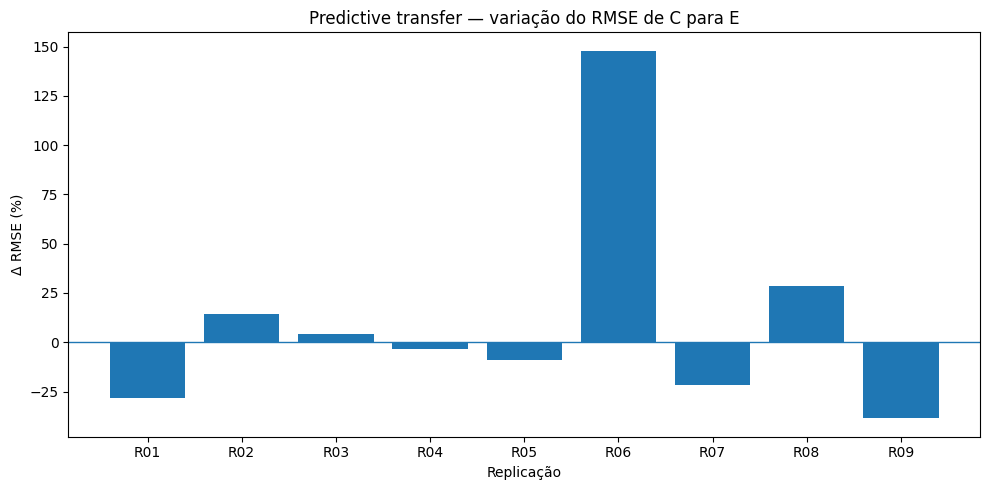

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.axhline(0, linewidth=1)
ax.bar(wide["replication"], wide["delta_RMSE_pct"])
ax.set_title("Predictive transfer — variação do RMSE de C para E")
ax.set_xlabel("Replicação")
ax.set_ylabel("Δ RMSE (%)")
plt.tight_layout()
plt.show()

In [13]:

representation_rows = []

for rep, g in pred.groupby("replication"):
    selected = selected_predictor.loc[
        selected_predictor["replication"] == rep, "selected_model"
    ].iloc[0]

    for (period, origin), z in g.groupby(["period", "origin"]):
        z = z.sort_values("horizon")

        mu = z[selected].to_numpy(dtype=float)

        
        
        sigma = z["ridge_sigma"].to_numpy(dtype=float)

        representation_rows.append({
            "replication": rep,
            "period": period,
            "origin": origin,
            "selected_predictor": selected,
            "mu_h1": mu[0] if len(mu) > 0 else np.nan,
            "mu_h2": mu[1] if len(mu) > 1 else np.nan,
            "mu_h3": mu[2] if len(mu) > 2 else np.nan,
            "mu_h4": mu[3] if len(mu) > 3 else np.nan,
            "sigma_h1": sigma[0] if len(sigma) > 0 else np.nan,
            "sigma_h2": sigma[1] if len(sigma) > 1 else np.nan,
            "sigma_h3": sigma[2] if len(sigma) > 2 else np.nan,
            "sigma_h4": sigma[3] if len(sigma) > 3 else np.nan,
            "burst_cv_24": z["burst_cv_24"].iloc[0],
        })

representation_inputs = pd.DataFrame(representation_rows)
display(representation_inputs.head())

,replication,period,origin,selected_predictor,mu_h1,mu_h2,mu_h3,mu_h4,sigma_h1,sigma_h2,sigma_h3,sigma_h4,burst_cv_24
0,R01,C,2024-04-26 00:00:00,seasonal24,59.0,70.0,32.0,13.0,51.480996,58.917298,56.97372,62.712549,0.704641
1,R01,C,2024-04-26 01:00:00,seasonal24,70.0,32.0,13.0,43.0,51.480996,58.917298,56.97372,62.712549,0.703821
2,R01,C,2024-04-26 02:00:00,seasonal24,32.0,13.0,43.0,42.0,51.480996,58.917298,56.97372,62.712549,0.706730
3,R01,C,2024-04-26 03:00:00,seasonal24,13.0,43.0,42.0,37.0,51.480996,58.917298,56.97372,62.712549,0.714669
4,R01,C,2024-04-26 04:00:00,seasonal24,43.0,42.0,37.0,24.0,51.480996,58.917298,56.97372,62.712549,0.715810


In [14]:
phi_sigma_grid = [0.0, 0.5, 1.0, 1.5, 2.0, 2.5]
phi_burst_grid = [0.0, 0.25, 0.50, 0.75]

phi_grid = pd.MultiIndex.from_product(
    [phi_sigma_grid, phi_burst_grid],
    names=["phi_sigma", "phi_burst"]
).to_frame(index=False)

print("Número de representações candidatas:", len(phi_grid))
display(phi_grid)

Número de representações candidatas: 24


,phi_sigma,phi_burst
0,0.0,0.00
1,0.0,0.25
2,0.0,0.50
3,0.0,0.75
4,0.5,0.00
5,0.5,0.25
6,0.5,0.50
7,0.5,0.75
8,1.0,0.00
9,1.0,0.25


In [15]:
pred.to_csv(OUT2 / "predictions_all_models.csv.gz", index=False, compression="gzip")
metrics_h.to_csv(OUT2 / "metrics_by_horizon.csv", index=False)
metrics.to_csv(OUT2 / "metrics_by_period.csv", index=False)
dev_scores.to_csv(OUT2 / "development_validation_scores.csv", index=False)
selected_predictor.to_csv(OUT2 / "selected_predictor_by_replication.csv", index=False)
wide.to_csv(OUT2 / "predictive_transfer.csv", index=False)
sigmas.to_csv(OUT2 / "ridge_uncertainty_by_replication.csv", index=False)
representation_inputs.to_csv(OUT2 / "representation_inputs.csv.gz", index=False, compression="gzip")
phi_grid.to_csv(OUT2 / "phi_grid_prespecified.csv", index=False)

summary = {
    "primary_gpu": PRIMARY_GPU,
    "horizon_hours": HORIZON,
    "n_replications": int(windows.shape[0]),
    "candidate_representation_count": int(phi_grid.shape[0]),
    "selected_predictors": selected_predictor[
        ["replication", "selected_model"]
    ].to_dict(orient="records"),
}

with open(OUT2 / "summary_02.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

print("Arquivos gerados em:", OUT2.resolve())
for p in sorted(OUT2.iterdir()):
    print(" -", p.name)

Arquivos gerados em: C:\Users\tiago\Dropbox\Artigos\FAME\FAME\Artigo 2 - AOR\FAME_GPU\outputs_fame_gpu_02
 - development_validation_scores.csv
 - metrics_by_horizon.csv
 - metrics_by_period.csv
 - phi_grid_prespecified.csv
 - predictions_all_models.csv.gz
 - predictive_transfer.csv
 - representation_inputs.csv.gz
 - ridge_uncertainty_by_replication.csv
 - selected_predictor_by_replication.csv
 - summary_02.json
